# MNIST Image Classification with TensorFlow

This notebook demonstrates how to implement a simple linear image models on MNIST using tf.keras.
<hr/>
This <a href="mnist_models.ipynb">companion notebook</a> extends the basic harness of this notebook to a variety of models including DNN, CNN, dropout, pooling etc.

In [2]:
!sudo chown jupyter:jupyter /home/jupyter/mnist_linear.ipynb

In [3]:
!pip install tensorflow-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.0/274.0 MB 104.3 MB/s  0:00:020:00:0100:01


In [4]:
import numpy as np
import shutil
import os
import tensorflow as tf
print(tf.__version__)

I0000 00:00:1795765995.949497    4597 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2.21.0


## Exploring the data

Let's download MNIST data and examine the shape. We will need these numbers ...

In [5]:
HEIGHT = 28
WIDTH = 28
NCLASSES = 10

In [6]:
# Get mnist data
mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Scale our features between 0 and 1
x_train, x_test = x_train / 255.0, x_test / 255.0 

# Convert labels to categorical one-hot encoding
y_train = tf.keras.utils.to_categorical(y_train, num_classes=NCLASSES)
y_test = tf.keras.utils.to_categorical(y_test, num_classes=NCLASSES)

print("x_train.shape = {}".format(x_train.shape))
print("y_train.shape = {}".format(y_train.shape))
print("x_test.shape = {}".format(x_test.shape))
print("y_test.shape = {}".format(y_test.shape))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train.shape = (60000, 28, 28)
y_train.shape = (60000, 10)
x_test.shape = (10000, 28, 28)
y_test.shape = (10000, 10)


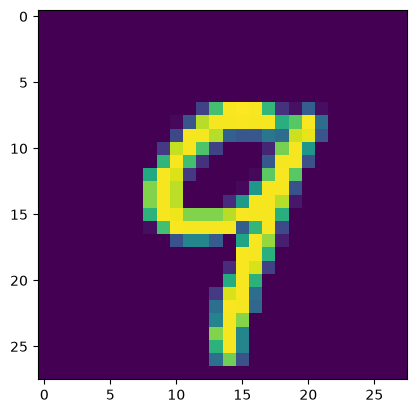

In [7]:
import matplotlib.pyplot as plt
IMGNO = 12
plt.imshow(x_test[IMGNO].reshape(HEIGHT, WIDTH));

## Define the model.
Let's start with a very simple linear classifier. All our models will have this basic interface -- they will take an image and return probabilities.

In [8]:
# Build Keras Model Using Keras Sequential API
def linear_model():
    model = tf.keras.models.Sequential()
    model.add(tf.keras.layers.InputLayer(input_shape = [HEIGHT, WIDTH], name = "image"))
    model.add(tf.keras.layers.Flatten())
    model.add(tf.keras.layers.Dense(units = NCLASSES, activation = tf.nn.softmax, name = "probabilities"))
    return model

## Write Input Functions

As usual, we need to specify input functions for training, evaluation, and predicition.

In [9]:
# Create training input function
train_dataset = (
    tf.data.Dataset.from_tensor_slices(({"image": x_train}, y_train))
    .shuffle(buffer_size=5000)
    .batch(100)
    .repeat()
    .prefetch(tf.data.AUTOTUNE)
)
# Create evaluation input function
eval_dataset = (
    tf.data.Dataset.from_tensor_slices(({"image": x_test}, y_test))
    .batch(100)
    .prefetch(tf.data.AUTOTUNE)
)

# Create serving input function for inference
@tf.function(input_signature=[
    {"image": tf.TensorSpec(shape=[None, HEIGHT, WIDTH], dtype=tf.float32, name="image")}
])
def serving_fn(inputs):
    return {"predictions": model(inputs)}

## Create train_and_evaluate function

 tf.estimator.train_and_evaluate does distributed training.

In [10]:
def train_and_evaluate(output_dir, hparams):
    # Build Keras model
    model = linear_model()
        
    # Compile Keras model with optimizer, loss function, and eval metrics
    model.compile(
        optimizer = "adam",
        loss = "categorical_crossentropy",
        metrics = ["accuracy"])
        
    # Train and evaluate model (replaces model_to_estimator, TrainSpec, EvalSpec, and train_and_evaluate)
    steps_per_epoch = 100
    epochs = max(1, hparams["train_steps"] // steps_per_epoch)

    model.fit(
        train_dataset,
        steps_per_epoch = steps_per_epoch,
        epochs = epochs,
        validation_data = eval_dataset)

    # Export saved_model for serving (replaces LatestExporter)
    @tf.function(input_signature=[
        {"image": tf.TensorSpec(shape=[None, HEIGHT, WIDTH], dtype=tf.float32, name="image")}
    ])
    def serving_fn(inputs):
        return {"predictions": model(inputs)}

    model.export(os.path.join(output_dir, "export", "exporter"), signatures={"serving_default": serving_fn})

This is the main() function

In [11]:
OUTDIR = "mnist/learned"
shutil.rmtree(OUTDIR, ignore_errors = True) # start fresh each time

hparams = {"train_steps": 1000, "learning_rate": 0.01}
train_and_evaluate(OUTDIR, hparams)

Epoch 1/10


/opt/micromamba/lib/python3.12/site-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/opt/micromamba/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
/opt/micromamba/lib/python3.12/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: image
Received: inputs=['Tensor(shape=(None, 28, 28))']
  warnings.warn(msg)


100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6867 - loss: 1.2775 - val_accuracy: 0.8333 - val_loss: 0.7754
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8383 - loss: 0.6747 - val_accuracy: 0.8757 - val_loss: 0.5424
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8723 - loss: 0.5269 - val_accuracy: 0.8893 - val_loss: 0.4579
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8722 - loss: 0.4730 - val_accuracy: 0.8968 - val_loss: 0.4109
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8840 - loss: 0.4343 - val_accuracy: 0.9005 - val_loss: 0.3836
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9046 - loss: 0.3603 - val_accuracy: 0.9046 - val_loss: 0.3631
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9005 - loss: 0.3653 - val_accuracy: 0.9059 - val_loss: 0.3531
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8983 - loss: 0.3703 - val_accuracy: 0.9079 - val_

INFO:tensorflow:Assets written to: mnist/learned/export/exporter/assets


Saved artifact at 'mnist/learned/export/exporter'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  140626563901648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140626563257872: TensorSpec(shape=(), dtype=tf.resource, name=None)


I got:

`Saving dict for global step 1000: categorical_accuracy = 0.9112, global_step = 1000, loss = 0.32516304`

In other words, we achieved 91.12% accuracy with the simple linear model!

<pre>
# Copyright 2020 Google Inc. All Rights Reserved.
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#      http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.
</pre>